# TP — Comptage d'occurrences de mots (WordCount)

Comparaison de trois approches :
1. **Python séquentiel simple**
2. **Pseudo-MapReduce en Python** (map → shuffle → reduce)
3. **Hadoop MapReduce** (distribué, HDFS + YARN)

Les trois méthodes sont d'abord testées sur le petit fichier du rapport, puis comparées sur **des fichiers de tailles croissantes** : un fichier de base de N lignes, puis des fichiers de m×N lignes obtenus par duplication.

**Environnement :** Manjaro Linux · Python 3.11 · Apache Hadoop 3.4.0

**Plan**
0. Données d'entrée
1. Version 1 : Python simple
2. Version 2 : Pseudo-MapReduce
3. Version 3 : Hadoop MapReduce
4. Fichiers de tailles croissantes (N, m×N)
5. Vérification avec une référence indépendante
6. Mesures de performance
7. Analyse
8. Conclusion

## 0. Données d'entrée
Fichier `mots.txt` du rapport (85 mots).

In [1]:
%%writefile mots.txt
montagne soleil arbre chien maison livre route chat
ciel chien mer montagne chat soleil chat chien
ciel jardin chat chat livre arbre livre maison
voiture fleur chat arbre arbre fleur chien chat
chat fleur mer chat chien lune chat chat
arbre fleur chat fleur chien chat chat maison
montagne lune chat montagne chat ciel fleur chat
montagne fleur chat soleil maison route arbre soleil
route maison chien mer livre chien chien lune
oiseau chat soleil chat ciel chat chat chien
chien arbre chat chat oiseau

Overwriting mots.txt


In [2]:
import os, time, glob, shutil, subprocess, statistics, random
from collections import defaultdict, Counter

with open('mots.txt', encoding='utf-8') as f:
    print(f"{len(f.read().split())} mots dans le fichier")

85 mots dans le fichier


## 1. Version 1 : Python simple
Lecture du fichier et comptage avec un dictionnaire.

In [3]:
def compter_occurrences(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

res_v1 = compter_occurrences('mots.txt')
for mot, nb in sorted(res_v1.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

chat : 24
chien : 11
arbre : 7
fleur : 7
montagne : 5
soleil : 5
maison : 5
livre : 4
ciel : 4
route : 3
mer : 3
lune : 3
oiseau : 2
jardin : 1
voiture : 1


## 2. Version 2 : Pseudo-MapReduce Python
- **map** : chaque ligne → liste de paires `(mot, 1)`
- **shuffle** : regroupement des valeurs par clé
- **reduce** : somme des valeurs pour chaque clé

In [4]:
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

def mapreduce_local(fichier):
    mapped = []
    with open(fichier, 'r', encoding='utf-8') as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))

# Détail des étapes sur le petit fichier
with open('mots.txt', encoding='utf-8') as f:
    mapped = [p for ligne in f for p in mapper(ligne)]
grouped = shuffle(mapped)
print('Sortie map (extrait)    :', mapped[:5])
print('Sortie shuffle (extrait):', {k: grouped[k] for k in list(grouped)[:3]})
print()
res_v2 = mapreduce_local('mots.txt')
for mot, nb in sorted(res_v2.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

Sortie map (extrait)    : [('montagne', 1), ('soleil', 1), ('arbre', 1), ('chien', 1), ('maison', 1)]
Sortie shuffle (extrait): {'montagne': [1, 1, 1, 1, 1], 'soleil': [1, 1, 1, 1, 1], 'arbre': [1, 1, 1, 1, 1, 1, 1]}

chat : 24
chien : 11
arbre : 7
fleur : 7
montagne : 5
soleil : 5
maison : 5
livre : 4
ciel : 4
route : 3
mer : 3
lune : 3
oiseau : 2
jardin : 1
voiture : 1


## 3. Version 3 : Hadoop MapReduce

### 3.1 Installation et démarrage (terminal)
```bash
sudo pacman -S jdk-openjdk
wget https://dlcdn.apache.org/hadoop/common/hadoop-3.4.0/hadoop-3.4.0.tar.gz
tar -xvzf hadoop-3.4.0.tar.gz && mv hadoop-3.4.0 ~/hadoop
echo 'export HADOOP_HOME=$HOME/hadoop' >> ~/.bashrc
echo 'export PATH=$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin' >> ~/.bashrc
source ~/.bashrc

hdfs namenode -format
start-dfs.sh
start-yarn.sh
```

### 3.2 Lancement depuis le notebook
La fonction `hadoop_wordcount` enchaîne les étapes du rapport (copie sur HDFS, `hadoop jar ... wordcount`, lecture de `part-r-00000`) et chronomètre séparément **la copie HDFS** et **le job**. Si HDFS n'est pas démarré, le job tourne en mode local sur le système de fichiers. Si Hadoop est absent, la fonction renvoie `None`.

In [5]:
HADOOP_HOME = os.environ.get('HADOOP_HOME', os.path.expanduser('~/hadoop'))
os.environ['HADOOP_HOME'] = HADOOP_HOME
if 'JAVA_HOME' not in os.environ and shutil.which('java'):
    java = os.path.realpath(shutil.which('java'))
    os.environ['JAVA_HOME'] = os.path.dirname(os.path.dirname(java))

HADOOP = shutil.which('hadoop') or os.path.join(HADOOP_HOME, 'bin', 'hadoop')
HDFS   = shutil.which('hdfs')   or os.path.join(HADOOP_HOME, 'bin', 'hdfs')
jars   = glob.glob(os.path.join(HADOOP_HOME, 'share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar'))
JAR    = jars[0] if jars else None
USER   = os.environ.get('USER', 'imad')

def sh(*cmd):
    return subprocess.run(list(cmd), capture_output=True, text=True)

HADOOP_DISPO = os.path.exists(HADOOP) and JAR is not None
HDFS_ACTIF = HADOOP_DISPO and sh(HDFS, 'dfs', '-ls', '/').returncode == 0
print(f"Hadoop installé : {HADOOP_DISPO} | HDFS démarré : {HDFS_ACTIF} | jar : {JAR}")

Hadoop installé : False | HDFS démarré : False | jar : None


In [6]:
def lire_sortie_hadoop(texte):
    """Convertit les lignes 'mot\tcompte' de part-r-* en dictionnaire."""
    res = {}
    for ligne in texte.splitlines():
        if '\t' in ligne:
            mot, nb = ligne.split('\t')
            res[mot] = int(nb)
    return res

def hadoop_wordcount(fichier, nom):
    """Renvoie (résultat, temps_copie_s, temps_job_s), ou (None, nan, nan)."""
    nan = float('nan')
    if not HADOOP_DISPO:
        return None, nan, nan

    if HDFS_ACTIF:
        entree = f'/user/{USER}/wordcount/{nom}/input'
        sortie = f'/user/{USER}/wordcount/{nom}/output'
        sh(HDFS, 'dfs', '-rm', '-r', '-f', f'/user/{USER}/wordcount/{nom}')
        t0 = time.perf_counter()
        sh(HDFS, 'dfs', '-mkdir', '-p', entree)
        sh(HDFS, 'dfs', '-put', '-f', fichier, entree + '/')
        t_copie = time.perf_counter() - t0
    else:  # mode local : pas de HDFS
        entree = 'file://' + os.path.abspath(fichier)
        dossier = os.path.abspath(f'hadoop_out/{nom}')
        shutil.rmtree(dossier, ignore_errors=True)
        sortie = 'file://' + dossier
        t_copie = 0.0

    t0 = time.perf_counter()
    job = sh(HADOOP, 'jar', JAR, 'wordcount', entree, sortie)
    t_job = time.perf_counter() - t0
    if job.returncode != 0:
        print('Le job Hadoop a échoué :\n', job.stderr[-600:])
        return None, t_copie, nan

    if HDFS_ACTIF:
        texte = sh(HDFS, 'dfs', '-cat', sortie + '/part-r-*').stdout
    else:
        texte = ''.join(open(p, encoding='utf-8').read() for p in glob.glob(dossier + '/part-r-*'))
    return lire_sortie_hadoop(texte), t_copie, t_job

res_v3, t_copie, t_job = hadoop_wordcount('mots.txt', 'rapport')
if res_v3 is not None:
    for mot, nb in sorted(res_v3.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    print(f"\nCopie HDFS : {t_copie:.2f} s | Job : {t_job:.2f} s")
else:
    print("Hadoop n'est pas disponible ici : lancer le notebook sur la machine où Hadoop est installé.")
    print("Pour mémoire, le rapport mesure 12 s pour ce fichier (interface YARN).")

Hadoop n'est pas disponible ici : lancer le notebook sur la machine où Hadoop est installé.
Pour mémoire, le rapport mesure 12 s pour ce fichier (interface YARN).


## 4. Fichiers de tailles croissantes
On génère un **fichier de base de N lignes** (même vocabulaire et mêmes fréquences relatives que `mots.txt`), puis des fichiers de **m×N lignes** en dupliquant ce fichier m fois.

Avec N = 10 000 lignes de 5 mots et m ∈ {1, 10, 50, 100}, on va de 50 000 à 5 millions de mots.

In [7]:
N = 10_000                  # lignes du fichier de base
MOTS_PAR_LIGNE = 5
M_VALEURS = [1, 10, 50, 100]  # facteurs de duplication

vocab, poids = zip(*Counter(open('mots.txt', encoding='utf-8').read().split()).items())

def creer_fichier_base(chemin, n_lignes, seed=0):
    rng = random.Random(seed)
    with open(chemin, 'w', encoding='utf-8') as f:
        for _ in range(n_lignes):
            f.write(' '.join(rng.choices(vocab, weights=poids, k=MOTS_PAR_LIGNE)) + '\n')

def dupliquer(source, m, chemin):
    with open(source, encoding='utf-8') as f:
        bloc = f.read()
    with open(chemin, 'w', encoding='utf-8') as f:
        f.write(bloc * m)

os.makedirs('donnees', exist_ok=True)
creer_fichier_base('donnees/base.txt', N)

fichiers = {}
for m in M_VALEURS:
    chemin = f'donnees/mots_{m}xN.txt'
    dupliquer('donnees/base.txt', m, chemin)
    fichiers[m] = chemin
    print(f"m = {m:>3} | {m*N:>9,} lignes | {m*N*MOTS_PAR_LIGNE:>10,} mots | {os.path.getsize(chemin)/1e6:6.2f} Mo")

m =   1 |    10,000 lignes |     50,000 mots |   0.30 Mo
m =  10 |   100,000 lignes |    500,000 mots |   2.96 Mo
m =  50 |   500,000 lignes |  2,500,000 mots |  14.80 Mo
m = 100 | 1,000,000 lignes |  5,000,000 mots |  29.59 Mo


## 5. Vérification avec une référence indépendante
`collections.Counter` sert de référence : il ne partage aucun code avec nos trois méthodes. On vérifie :
1. que les trois méthodes donnent exactement le résultat de `Counter` (petit fichier et fichier de base) ;
2. que la duplication est cohérente : **comptage(m×N) = m × comptage(N)** pour chaque m.

In [8]:
def reference(fichier):
    with open(fichier, encoding='utf-8') as f:
        return dict(Counter(f.read().split()))

for fichier in ['mots.txt', 'donnees/base.txt']:
    ref = reference(fichier)
    assert compter_occurrences(fichier) == ref, f'V1 incorrecte sur {fichier}'
    assert mapreduce_local(fichier) == ref, f'V2 incorrecte sur {fichier}'
    r3, _, _ = hadoop_wordcount(fichier, 'verif_' + os.path.basename(fichier).split('.')[0])
    statut_h = 'non testé (Hadoop absent)' if r3 is None else ('OK' if r3 == ref else 'DIFFÉRENT')
    assert r3 is None or r3 == ref, f'Hadoop incorrect sur {fichier}'
    print(f"{fichier:<18} V1 OK | V2 OK | Hadoop {statut_h}")

ref_base = reference('donnees/base.txt')
for m, chemin in fichiers.items():
    attendu = {mot: m * nb for mot, nb in ref_base.items()}
    assert compter_occurrences(chemin) == attendu, f'Incohérence pour m={m}'
print('\ncomptage(m×N) = m × comptage(N) vérifié pour m =', M_VALEURS)

mots.txt           V1 OK | V2 OK | Hadoop non testé (Hadoop absent)
donnees/base.txt   V1 OK | V2 OK | Hadoop non testé (Hadoop absent)

comptage(m×N) = m × comptage(N) vérifié pour m = [1, 10, 50, 100]


## 6. Mesures de performance
Chaque méthode est lancée sur **le même fichier**, pour chaque taille.
- **Python** : médiane de 3 exécutions avec `time.perf_counter()` (le temps de démarrage de l'interpréteur n'est pas compté, contrairement à la commande `time` du rapport).
- **Hadoop** : une exécution de bout en bout ; on note à part le temps de copie sur HDFS. Une seule mesure suffit, car le coût de démarrage domine largement la variance.

In [9]:
def mediane_temps(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        resultat = fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), resultat

mesures = []
for m, chemin in fichiers.items():
    t1, r1 = mediane_temps(compter_occurrences, chemin)
    t2, r2 = mediane_temps(mapreduce_local, chemin)
    r3, tc, t3 = hadoop_wordcount(chemin, f'm{m}')
    assert r1 == r2 and (r3 is None or r3 == r1)
    mesures.append({'m': m, 'lignes': m * N, 'mots': m * N * MOTS_PAR_LIGNE,
                    'Mo': os.path.getsize(chemin) / 1e6,
                    'Python simple (s)': t1, 'Pseudo-MapReduce (s)': t2,
                    'Hadoop job (s)': t3, 'Copie HDFS (s)': tc})
    print(f'm = {m:>3} mesuré')

m =   1 mesuré
m =  10 mesuré
m =  50 mesuré
m = 100 mesuré


In [10]:
import pandas as pd

df = pd.DataFrame(mesures)
df['Surcoût pseudo-MR (×)'] = df['Pseudo-MapReduce (s)'] / df['Python simple (s)']
df['Hadoop / Python simple (×)'] = df['Hadoop job (s)'] / df['Python simple (s)']
df.style.format({'Mo': '{:.2f}', 'Python simple (s)': '{:.4f}', 'Pseudo-MapReduce (s)': '{:.4f}',
                 'Hadoop job (s)': '{:.2f}', 'Copie HDFS (s)': '{:.2f}',
                 'Surcoût pseudo-MR (×)': '{:.2f}', 'Hadoop / Python simple (×)': '{:.0f}',
                 'lignes': '{:,}', 'mots': '{:,}'}, na_rep='—')

,m,lignes,mots,Mo,Python simple (s),Pseudo-MapReduce (s),Hadoop job (s),Copie HDFS (s),Surcoût pseudo-MR (×),Hadoop / Python simple (×)
0,1,"10,000","50,000",0.30,0.0061,0.0122,—,—,2.00,—
1,10,"100,000","500,000",2.96,0.0766,0.1461,—,—,1.91,—
2,50,"500,000","2,500,000",14.80,0.3873,0.9109,—,—,2.35,—
3,100,"1,000,000","5,000,000",29.59,0.8429,1.5678,—,—,1.86,—


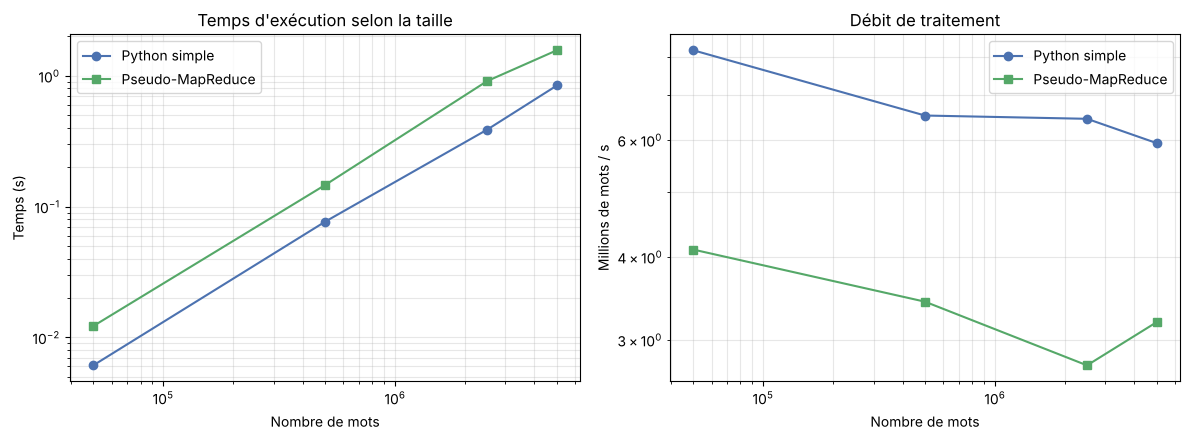

In [11]:
import matplotlib.pyplot as plt

methodes = [('Python simple (s)', 'Python simple', 'o', '#4C72B0'),
            ('Pseudo-MapReduce (s)', 'Pseudo-MapReduce', 's', '#55A868'),
            ('Hadoop job (s)', 'Hadoop MapReduce', '^', '#C44E52')]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for col, nom, marqueur, couleur in methodes:
    if df[col].notna().any():
        ax1.plot(df['mots'], df[col], marker=marqueur, color=couleur, label=nom)
        ax2.plot(df['mots'], df['mots'] / df[col] / 1e6, marker=marqueur, color=couleur, label=nom)

ax1.set(xscale='log', yscale='log', xlabel='Nombre de mots', ylabel='Temps (s)',
        title="Temps d'exécution selon la taille")
ax2.set(xscale='log', yscale='log', xlabel='Nombre de mots', ylabel='Millions de mots / s',
        title='Débit de traitement')
for ax in (ax1, ax2):
    ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [12]:
# Chiffres clés utilisés dans l'analyse
premier, dernier = df.iloc[0], df.iloc[-1]
facteur_taille = dernier['mots'] / premier['mots']
print(f"Taille multipliée par {facteur_taille:.0f}")
print(f"  Python simple    : temps × {dernier['Python simple (s)'] / premier['Python simple (s)']:.0f}")
print(f"  Pseudo-MapReduce : temps × {dernier['Pseudo-MapReduce (s)'] / premier['Pseudo-MapReduce (s)']:.0f}")
if df['Hadoop job (s)'].notna().all():
    print(f"  Hadoop           : temps × {dernier['Hadoop job (s)'] / premier['Hadoop job (s)']:.1f}")
print(f"Surcoût pseudo-MR : de {df['Surcoût pseudo-MR (×)'].min():.1f}× à {df['Surcoût pseudo-MR (×)'].max():.1f}×")

Taille multipliée par 100
  Python simple    : temps × 138
  Pseudo-MapReduce : temps × 129
Surcoût pseudo-MR : de 1.9× à 2.4×


## 7. Analyse

**Python simple vs pseudo-MapReduce.** Les deux temps croissent à peu près proportionnellement à la taille du fichier. La version pseudo-MapReduce reste plus lente d'un facteur de l'ordre de 2 à 3 : elle construit une liste de toutes les paires `(mot, 1)`, puis une liste de `1` par mot dans `shuffle`, avant de les additionner. Ce surcoût porte aussi sur la **mémoire** : toutes les paires intermédiaires sont stockées en même temps, ce qui devient le facteur limitant sur de gros fichiers.

**Hadoop : un coût fixe qui s'amortit.** Hadoop paie plusieurs secondes à chaque job, quelle que soit la taille : démarrage de la JVM, soumission du job à YARN, allocation des conteneurs, écriture du résultat sur HDFS. À cela s'ajoute la copie des données sur HDFS. Sur le petit fichier du rapport, cela donne 12 s contre 0,012 s, soit un facteur d'environ 1000. Quand la taille augmente, le temps Hadoop croît **beaucoup plus lentement** que celui de Python, car la part du coût fixe diminue : le rapport Hadoop / Python baisse avec m.

**Limites du mode local.** Ici, Hadoop tourne sur une seule machine (mode pseudo-distribué). Il n'y a donc ni vrai parallélisme sur plusieurs nœuds, ni gain de distribution : le point où Hadoop dépasse Python n'est généralement pas atteint avec quelques dizaines de Mo. Son intérêt apparaît sur un vrai cluster, avec des données de l'ordre du Go ou plus, notamment **plus grandes que la RAM**, ce que les versions Python ne savent pas traiter.

## 8. Conclusion

| Critère | Python simple | Pseudo-MapReduce | Hadoop MapReduce |
|---|---|---|---|
| Mise en œuvre | quelques lignes | quelques fonctions | installation et configuration lourdes |
| Petits fichiers (Ko → quelques Mo) | **le plus rapide** | rapide, surcoût ×2 à ×3 | très lent (coût fixe de plusieurs secondes) |
| Fichiers moyens (dizaines à centaines de Mo) | rapide tant que la RAM suffit | plus lent et gourmand en mémoire | coût fixe amorti, mais pas de gain sur une seule machine |
| Très gros volumes (Go → To, > RAM) | impossible (tout en mémoire) | impossible (paires intermédiaires en mémoire) | **adapté** : blocs HDFS, parallélisme, tolérance aux pannes |
| Intérêt pédagogique | référence | comprendre map / shuffle / reduce | environnement réel de production |

Les trois approches donnent exactement le même résultat. Elles forment une progression naturelle : la **simplicité** du traitement local, la **modularité** du modèle MapReduce simulé, puis la **puissance** du traitement distribué, qui n'est rentable que sur de gros volumes.